In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df=pd.read_csv("C:/Users/alokk/Downloads/heart.csv")
df.head(3)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


In [4]:
df=df.rename(columns={"Sex":"gender"})
df.head(3)

,Age,gender,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


In [5]:
df.shape

(918, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   gender          918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
df=df[["Age","gender","Cholesterol","MaxHR","ChestPainType","RestingBP","HeartDisease"]]
df.head()

,Age,gender,Cholesterol,MaxHR,ChestPainType,RestingBP,HeartDisease
0,40,M,289,172,ATA,140,0
1,49,F,180,156,NAP,160,1
2,37,M,283,98,ATA,130,0
3,48,F,214,108,ASY,138,1
4,54,M,195,122,NAP,150,0


In [9]:
df.isnull().sum()

Age              0
gender           0
Cholesterol      0
MaxHR            0
ChestPainType    0
RestingBP        0
HeartDisease     0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(1)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 917 entries, 0 to 917
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            917 non-null    int64
 1   gender         917 non-null    str  
 2   Cholesterol    917 non-null    int64
 3   MaxHR          917 non-null    int64
 4   ChestPainType  917 non-null    str  
 5   RestingBP      917 non-null    int64
 6   HeartDisease   917 non-null    int64
dtypes: int64(5), str(2)
memory usage: 61.1 KB


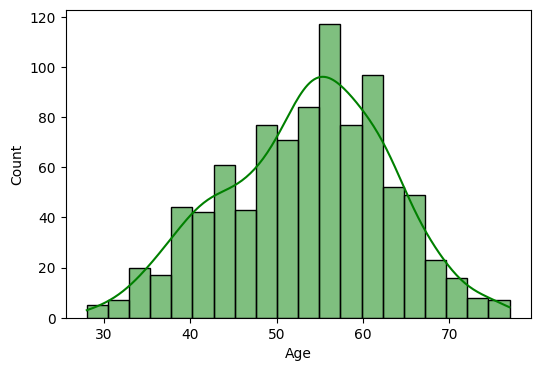

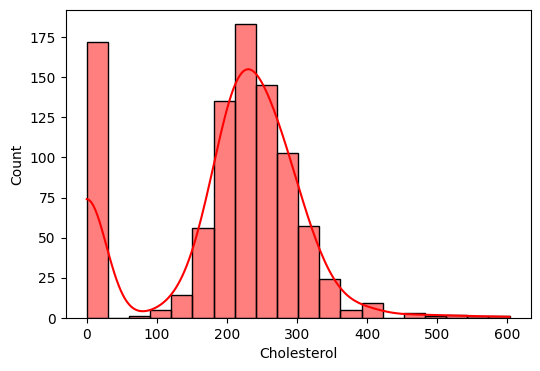

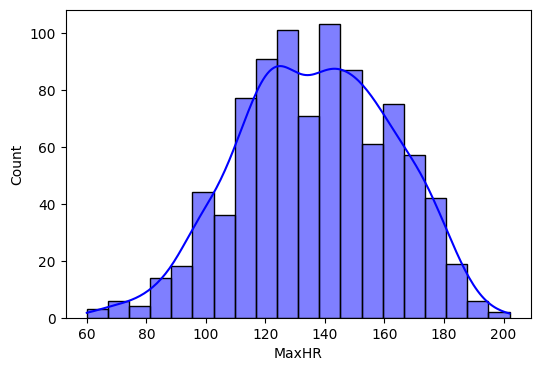

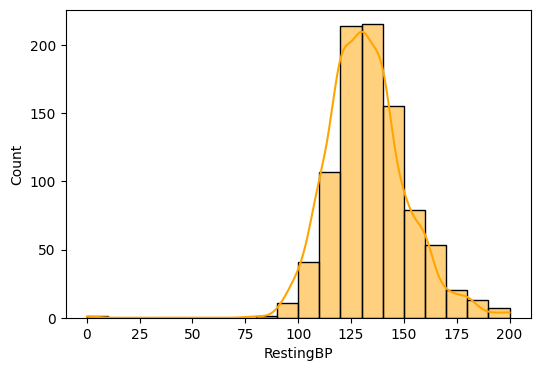

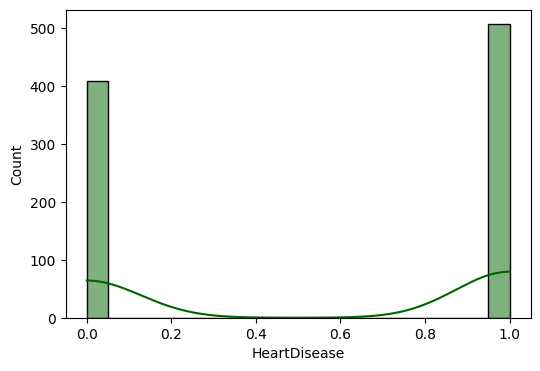

In [14]:
my=["Age","Cholesterol","MaxHR","RestingBP","HeartDisease"]
color=["green","red","blue","orange","darkgreen"]
for i ,c in zip(my,color):
    plt.figure(figsize=(6,4))
    sns.histplot(df[i],kde=True,bins=20,color=c)

<Axes: xlabel='gender', ylabel='count'>

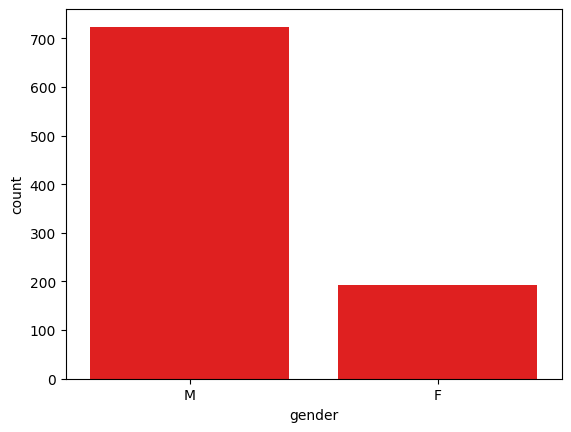

In [15]:
sns.countplot(x="gender",data=df,color="red")

In [16]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["gender"]=le.fit_transform(df["gender"])


In [17]:
df.head(2)

,Age,gender,Cholesterol,MaxHR,ChestPainType,RestingBP,HeartDisease
0,40,1,289,172,ATA,140,0
1,49,0,180,156,NAP,160,1


In [18]:
df=pd.get_dummies(df,columns=["ChestPainType"],dtype=int)

In [19]:
df.head(3)

,Age,gender,Cholesterol,MaxHR,RestingBP,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA
0,40,1,289,172,140,0,0,1,0,0
1,49,0,180,156,160,1,0,0,1,0
2,37,1,283,98,130,0,0,1,0,0


In [20]:
df["HeartDisease"].value_counts()

HeartDisease
1    507
0    410
Name: count, dtype: int64

In [21]:
from sklearn.preprocessing import StandardScaler 
column=["Age","Cholesterol","MaxHR","RestingBP"]
scaler=StandardScaler()
df[column]=scaler.fit_transform(df[column])

In [22]:
df.head()

,Age,gender,Cholesterol,MaxHR,RestingBP,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA
0,-1.431979,1,0.824499,1.382323,0.410548,0,0,1,0,0
1,-0.477596,0,-0.171996,0.753889,1.490812,1,0,0,1,0
2,-1.750106,1,0.769646,-1.524184,-0.129585,0,0,1,0,0
3,-0.583639,0,0.138837,-1.131412,0.302521,1,1,0,0,0
4,0.052617,1,-0.034864,-0.581533,0.950680,0,0,0,1,0


# featuer set

In [23]:
x=df[["Age","gender","Cholesterol","MaxHR","RestingBP","ChestPainType_ASY","ChestPainType_ATA","ChestPainType_NAP","ChestPainType_TA"]]
y=df["HeartDisease"]

In [24]:
from sklearn.model_selection import train_test_split 
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [25]:
from sklearn.linear_model import LogisticRegression 
model=LogisticRegression()
model.fit(x_train,y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [26]:
trainscore=model.score(x_train,y_train)

In [27]:
pre=model.predict(x_test)

In [28]:
testscore=model.score(x_test,y_test)

C:\Users\alokk\AppData\Local\Temp\ipykernel_10652\1394435139.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["TRAIN SCORE","TEST SCORE"],y=[trainscore,testscore],palette=["r","g"])


<Axes: >

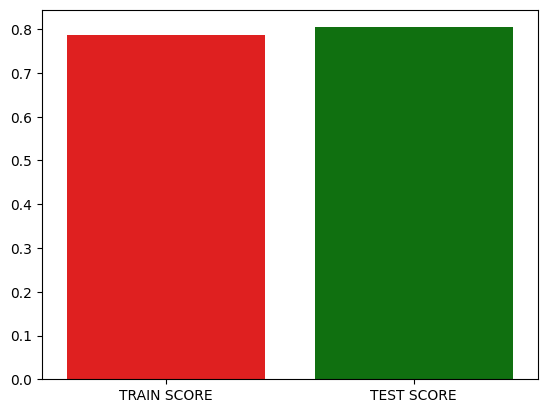

In [29]:
sns.barplot(x=["TRAIN SCORE","TEST SCORE"],y=[trainscore,testscore],palette=["r","g"])


<BarContainer object of 2 artists>

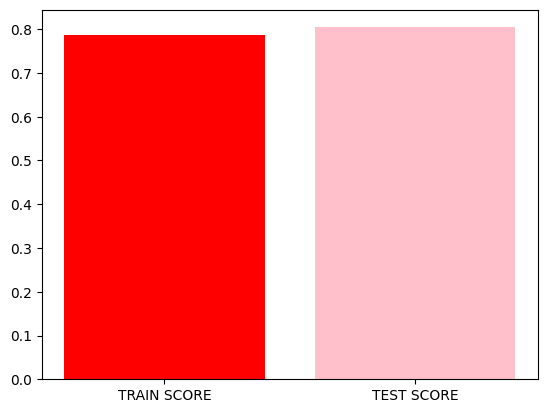

In [32]:
x=["TRAIN SCORE","TEST SCORE"]
y=[trainscore,testscore]
plt.bar(x,y,color=["red","pink"])

In [ ]:
import pickle 
pickle.dump(model,open("heart.pkl","wb"))
pickle.dump(scaler,open("scler.pkl","wb"))
print("successfully")

successfully
